In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
base=['engine_displacement',
'horsepower',
'vehicle_weight',
'model_year']
df[base]

,engine_displacement,horsepower,vehicle_weight,model_year
0,2180,243.0,3870,2006
1,2390,272.0,4210,2008
2,2320,267.0,4240,1996
3,2130,258.0,4490,1989
4,2580,304.0,4510,1994
...,...,...,...,...
9995,2470,271.0,4690,2005
9996,2300,244.0,4370,1993
9997,2480,267.0,4590,2014
9998,2180,270.0,4450,2004


<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

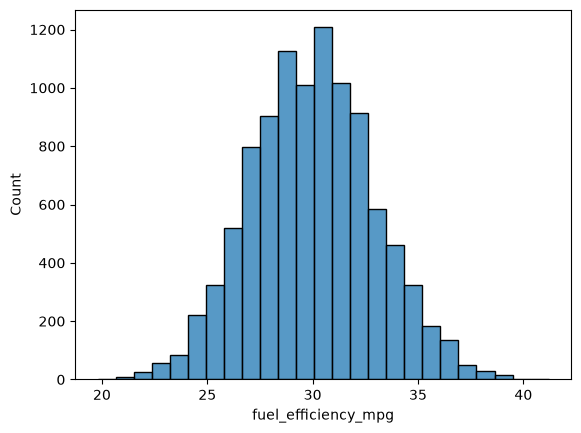

In [5]:
#EDA
sns.histplot(df["fuel_efficiency_mpg"],bins=25)

In [6]:
skewness=df["fuel_efficiency_mpg"].skew()
skewness
# no long tail

np.float64(0.08080419601878173)

In [7]:
#missing values
df.isnull().sum()
#horsepower=877

model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
dtype: int64

In [8]:
df["horsepower"].mean()

np.float64(254.44601556505535)

In [9]:
#df["horsepower"].fillna(0).mean()

In [10]:
#df["horsepower"].fillna(df["horsepower"].mean()).mean()

In [11]:
n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_test-n_val
np.random.seed(41)
idx=np.arange(n)
np.random.shuffle(idx)
df_val=df.iloc[idx[:n_val]].copy()
df_test=df.iloc[idx[n_val:n_test+n_val]].copy()
df_train=df.iloc[idx[n_val+n_test:]].copy()
df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
6736,1998,Europe,Gasoline,Rear-wheel drive,4,1830,5,208.0,4110,17.2,31.5
1929,1985,USA,Diesel,All-wheel drive,2,2130,6,263.0,4090,18.6,26.8
5602,2015,USA,Gasoline,Front-wheel drive,2,2040,5,247.0,3830,17.6,30.6
1007,2005,USA,Gasoline,Front-wheel drive,2,2250,6,245.0,4070,17.8,29.9
6839,2012,Asia,Diesel,Front-wheel drive,3,1950,5,245.0,3710,18.4,35.6
...,...,...,...,...,...,...,...,...,...,...,...
8513,1988,USA,Diesel,Front-wheel drive,4,2300,6,282.0,4400,20.0,30.1
5200,2018,USA,Gasoline,Front-wheel drive,3,2190,6,248.0,4080,18.8,28.1
4066,1980,Europe,Gasoline,Rear-wheel drive,3,2160,6,256.0,4120,19.7,28.6
931,1985,USA,Gasoline,Front-wheel drive,3,2320,7,270.0,4280,20.3,26.8


In [12]:
df_train=df_train.reset_index(drop=True)
df_val=df_val.reset_index(drop=True)
df_test=df_test.reset_index(drop=True)
df_train

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,1998,Europe,Gasoline,Rear-wheel drive,4,1830,5,208.0,4110,17.2,31.5
1,1985,USA,Diesel,All-wheel drive,2,2130,6,263.0,4090,18.6,26.8
2,2015,USA,Gasoline,Front-wheel drive,2,2040,5,247.0,3830,17.6,30.6
3,2005,USA,Gasoline,Front-wheel drive,2,2250,6,245.0,4070,17.8,29.9
4,2012,Asia,Diesel,Front-wheel drive,3,1950,5,245.0,3710,18.4,35.6
...,...,...,...,...,...,...,...,...,...,...,...
5995,1988,USA,Diesel,Front-wheel drive,4,2300,6,282.0,4400,20.0,30.1
5996,2018,USA,Gasoline,Front-wheel drive,3,2190,6,248.0,4080,18.8,28.1
5997,1980,Europe,Gasoline,Rear-wheel drive,3,2160,6,256.0,4120,19.7,28.6
5998,1985,USA,Gasoline,Front-wheel drive,3,2320,7,270.0,4280,20.3,26.8


In [13]:
y_train=np.log1p(df_train.fuel_efficiency_mpg.values)
y_val=np.log1p(df_val.fuel_efficiency_mpg.values)
y_test=np.log1p(df_test.fuel_efficiency_mpg.values)

In [14]:
def linear_regression(X,Y):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    XTX=X.T.dot(X)
    XTX_inv=np.linalg.inv(XTX)
    W_full=XTX_inv.dot(X.T).dot(Y)
    return W_full[0],W_full[1:]

In [15]:
def prepare_x_0(df):
    df_nums = df[base].copy()
    df_nums=df_nums.fillna(0)
    X=df_nums.values
    return X
def RSME (y,y_pred):
    se=(y-y_pred)**2
    mse=se.mean()
    return np.sqrt(mse)
def prepare_x_mean(df):
    df_nums = df[base].copy()
    df_nums['horsepower']= df_nums['horsepower'].fillna(df_nums['horsepower'].mean())
    X=df_nums.values
    return X    


       

In [16]:
X_train_0=prepare_x_0(df_train)
w0_0,w_0=linear_regression(X_train_0,y_train)
y_pred=w0_0+X_train_0.dot(w_0)
train_rmse_0=round(RSME(y_train,y_pred),3)

In [17]:
X_train_mean=prepare_x_mean(df_train)
w0_mean,w_mean=linear_regression(X_train_mean,y_train)
y_pred=w0_mean+X_train_mean.dot(w_mean)
train_rmse_mean=round(RSME(y_train,y_pred),3)

In [18]:
matrices_are_equal = np.allclose(X_train_0, X_train_mean)
print("Are the feature matrices identical?", matrices_are_equal)

Are the feature matrices identical? False


In [19]:
print(f"Training RMSE (Fill with 0):    {train_rmse_0:.10f}")
print(f"Training RMSE (Fill with Mean): {train_rmse_mean:.10f}")

Training RMSE (Fill with 0):    0.0710000000
Training RMSE (Fill with Mean): 0.0710000000


In [20]:
print("Are the weights identical?", np.allclose(w_0, w_mean))
print("Intercepts - 0:", w0_0, "| Mean:", w0_mean)
print("Mean value used for horsepower:", df_train["horsepower"].mean())

Are the weights identical? False
Intercepts - 0: -2.5518040954581114 | Mean: -2.532575222709469
Mean value used for horsepower: 254.6287643730608


In [21]:
def linear_regression_reg(X,Y,r):
    ones=np.ones(X.shape[0])
    X=np.column_stack([ones,X])
    XTX=X.T.dot(X)
    XTX=XTX+r*np.eye(XTX.shape[0])
    XTX_inv=np.linalg.inv(XTX)
    W_full=XTX_inv.dot(X.T).dot(Y)
    return W_full[0],W_full[1:]

In [22]:
X_train_0=prepare_x_0(df_train)
reg=[0, 0.01, 0.1, 1, 5, 10, 100]
rsme=[]
for r in reg:
    w0_0,w_0=linear_regression_reg(X_train_0,y_train,r)
    y_pred=w0_0+X_train_0.dot(w_0)
    train_rmse_0=round(RSME(y_train,y_pred),3)
    rsme.append(train_rmse_0)
rsme

[np.float64(0.071),
 np.float64(0.071),
 np.float64(0.071),
 np.float64(0.073),
 np.float64(0.073),
 np.float64(0.073),
 np.float64(0.073)]

In [30]:
n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_test-n_val
scores=[]
seeds_values=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
for s in seeds_values:
    np.random.seed(s)
    idx=np.arange(n)
    np.random.shuffle(idx)
    df_val=df.iloc[idx[:n_val]].copy()
    df_test=df.iloc[idx[n_val:n_test+n_val]].copy()
    df_train=df.iloc[idx[n_val+n_test:]].copy()
    y_train=np.log1p(df_train.fuel_efficiency_mpg.values)
    y_val=np.log1p(df_val.fuel_efficiency_mpg.values)
    y_test=np.log1p(df_test.fuel_efficiency_mpg.values)
    X_train_0=prepare_x_0(df_train)
    X_val_0=prepare_x_0(df_val)
    w0_0,w_0=linear_regression(X_train_0,y_train)
    
    y_pred=w0_0+X_val_0.dot(w_0)
    val_rmse_0=RSME(y_val,y_pred)
    scores.append(val_rmse_0)
scores      
    

[np.float64(0.07024870580462579),
 np.float64(0.0692298909078985),
 np.float64(0.07273288803305705),
 np.float64(0.07083847676352496),
 np.float64(0.07160229059253514),
 np.float64(0.07133411065641823),
 np.float64(0.06972355844339267),
 np.float64(0.07146868007292552),
 np.float64(0.07191820464953516),
 np.float64(0.07211457918636456)]

In [32]:
std_val = round(float(np.std(scores)), 3)
print("Scores:", scores)
print("Standard Deviation:", std_val)

Scores: [np.float64(0.07024870580462579), np.float64(0.0692298909078985), np.float64(0.07273288803305705), np.float64(0.07083847676352496), np.float64(0.07160229059253514), np.float64(0.07133411065641823), np.float64(0.06972355844339267), np.float64(0.07146868007292552), np.float64(0.07191820464953516), np.float64(0.07211457918636456)]
Standard Deviation: 0.001


In [40]:

n=len(df)
n_val=int(n*0.2)
n_test=int(n*0.2)
n_train=n-n_test-n_val
np.random.seed(9)
idx=np.arange(n)
np.random.shuffle(idx)
df_val=df.iloc[idx[:n_val]].copy()
df_test=df.iloc[idx[n_val:n_test+n_val]].copy()
df_train=df.iloc[idx[n_val+n_test:]].copy()
df_full_train=pd.concat([df_train,df_val])
df_full_train=df_full_train.reset_index(drop=True)
y_full_train=np.concatenate([y_train,y_val])
X_test_0=prepare_x_0(df_test)
X_full_train_0=prepare_x_0(df_full_train)
w0_0,w_0=linear_regression_reg(X_full_train_0,y_full_train,0.001)
y_pred=w0_0+X_test_0.dot(w_0)
test_rmse_0=RSME(y_test,y_pred)
test_rmse_0
   


np.float64(0.07043922701126057)

In [41]:
y_pred_orig = np.expm1(w0_0 + X_test_0.dot(w_0))
y_test_orig = np.expm1(y_test)
original_rmse = RSME(y_test_orig, y_pred_orig)
print('Original Scale RMSE:', original_rmse)

Original Scale RMSE: 2.169897414286853
